#**Practical Assignment-03 Performance Evaluation of Regression Model**

Name: Arya M. Bhat

Div: A Batch: A1

Roll no :10

PRN : 202401040044

##**Problem Statement**

The objective of this practical is to implement and evaluate different regression techniques using the California Housing Dataset to predict median house values. The practical focuses on understanding the working principles of regression algorithms, implementing models using mathematical approaches and machine learning libraries, and comparing their performance using suitable evaluation metrics.

##**Objectives**
1. To understand the concepts and applications of regression in machine learning.
2. To implement Simple Linear Regression and Multiple Linear Regression.
3. To understand and implement Gradient Descent for model optimization.
4. To explore Polynomial Regression and Locally Weighted Linear Regression.
5. To evaluate regression models using Mean Squared Error (MSE), Mean Absolute Error (MAE) and R² Score.
6. To compare different regression models and identify their performance differences.
7. To understand the applications and limitations of regression techniques in real-world problems.


**1. Import libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


##**Dataset Description**

The California Housing Dataset is used in this practical to develop regression models for predicting median house values in different California districts.

The dataset contains information about housing characteristics, geographical location, population and income levels.

The important attributes include:
- Longitude and Latitude: Geographical location of the housing district.
- Housing Median Age: Median age of houses in the district.
- Total Rooms: Total number of rooms in the district.
- Total Bedrooms: Total number of bedrooms.
- Population: Total population of the district.
- Households: Number of households.
- Median Income: Median income of households.
- Median House Value: Target variable representing the median house value.
- Ocean Proximity: Category describing the district's proximity to the ocean.
In this practical, median house value is considered the dependent variable, while different housing characteristics are used as independent variables.

The dataset is suitable for regression analysis because the target variable is continuous and can be predicted using the available numerical and categorical features.

**2. Loading the dataset**

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving housing.csv to housing.csv
Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

# Fill missing numerical values with their median
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].median()
)

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   h

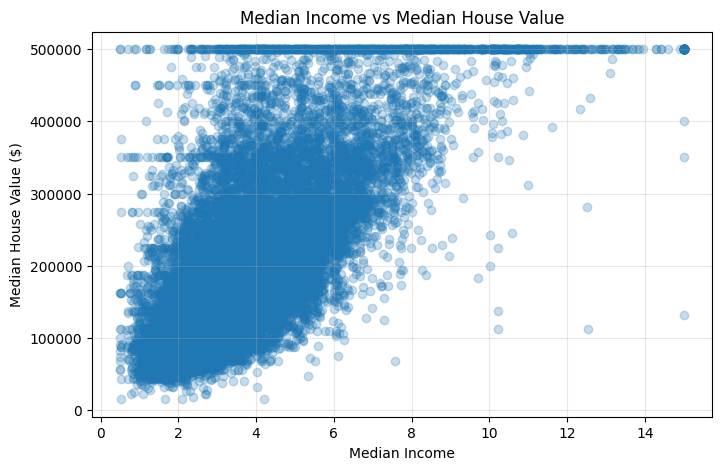

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.25
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")
plt.title("Median Income vs Median House Value")
plt.grid(True, alpha=0.3)
plt.show()

##**Part A- Simple Linear Regression**

**3. Theory and model selection**
Simple linear regression predicts one dependent variable using one independent variable.

The equation is:
\[
\hat y = mx+c
\]

Where:
- \(x\): independent variable — median_income
- \(y\): actual target — median_house_value
- \(m\): slope of the line
- \(c\): intercept
- \(\hat y\): predicted house value
We select median_income as the input because it has an understandable relationship with housing prices and makes the model easy to visualize.

**4. Split the dataset into training and testing data**

We use an 80:20 split. The model learns from the training set and is evaluated on unseen test data.

In [ ]:
X = df[["median_income"]].to_numpy()
y = df["median_house_value"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


**5. Implement linear regression without a machine-learning library**

Here, we calculate the slope and intercept using the mathematical formulas rather than sklearn.LinearRegression.
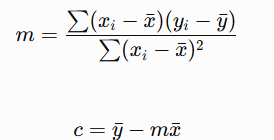

In [ ]:
# Convert the single feature into a 1D array
x_train = X_train.ravel()
x_test = X_test.ravel()

# Calculate means using training data only
x_mean = np.mean(x_train)
y_mean = np.mean(y_train)

# Calculate slope
numerator = np.sum((x_train - x_mean) * (y_train - y_mean))
denominator = np.sum((x_train - x_mean) ** 2)

m = numerator / denominator

# Calculate intercept
c = y_mean - m * x_mean

print("Slope (m):", m)
print("Intercept (c):", c)

# Predict on test data
y_pred_manual = m * x_test + c

print("\nFirst 5 actual values:", y_test[:5])
print("First 5 predictions:", y_pred_manual[:5])

Slope (m): 41933.8493938127
Intercept (c): 44459.72916907884

First 5 actual values: [ 47700.  45800. 500001. 218600. 278000.]
First 5 predictions: [114958.91676996 150606.88213964 190393.71844449 285059.38345102
 200663.31816103]


**6. Calculate MSE and MAE without metric libraries**

These are the two required performance metrics.

**Mean Squared Error (MSE)**
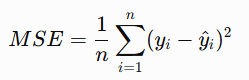

MSE squares every prediction error. Larger errors therefore have a disproportionately large effect. Its unit is dollars squared for this dataset.

**Mean Absolute Error (MAE)**
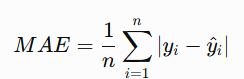

MAE gives the average absolute prediction error in dollars, making it easier to interpret.

In [ ]:
errors = y_test - y_pred_manual

mse_manual = np.mean(errors ** 2)
mae_manual = np.mean(np.abs(errors))

print("Manual MSE:", mse_manual)
print("Manual MAE:", mae_manual)

Manual MSE: 7091157771.76555
Manual MAE: 62990.86530093761


Interpretation:
- Lower MSE generally means better prediction performance, particularly when large errors matter.
- Lower MAE means predictions are closer to actual values on average.
- Neither metric alone proves that a model generalizes well; both must be calculated on unseen test data.

**7. Implement linear regression using a library**

Now we use sklearn.LinearRegression and evaluate the same split. This is how you demonstrate both manual and library-based implementation.

In [ ]:
model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

y_pred_sklearn = model_lr.predict(X_test)

mse_sklearn = mean_squared_error(y_test, y_pred_sklearn)
mae_sklearn = mean_absolute_error(y_test, y_pred_sklearn)
r2_sklearn = r2_score(y_test, y_pred_sklearn)

print("Slope:", model_lr.coef_[0])
print("Intercept:", model_lr.intercept_)

print("\nMSE:", mse_sklearn)
print("MAE:", mae_sklearn)
print("R² Score:", r2_sklearn)

Slope: 41933.84939381272
Intercept: 44459.72916907875

MSE: 7091157771.76555
MAE: 62990.86530093761
R² Score: 0.45885918903846656


**8. Plot the regression line**

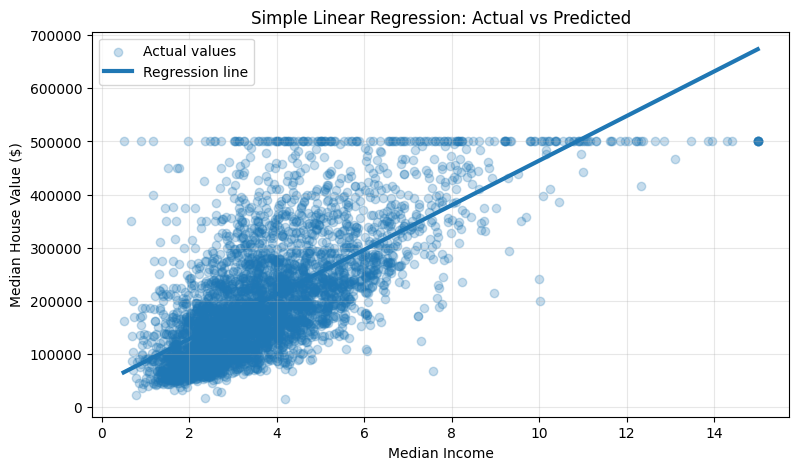

In [ ]:
order = np.argsort(X_test[:, 0])

plt.figure(figsize=(9, 5))

plt.scatter(
    X_test[:, 0],
    y_test,
    alpha=0.25,
    label="Actual values"
)

plt.plot(
    X_test[order, 0],
    y_pred_sklearn[order],
    linewidth=3,
    label="Regression line"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The scatter points represent actual house values. The straight line represents predictions. The distance between a point and the line represents its prediction error.

##**Part B — Gradient Descent for Linear Regression**

Instead of calculating the best slope and intercept directly, gradient descent starts with initial parameters and repeatedly updates them to reduce the Mean Squared Error.

For the model \(\hat y=wx+b\), the gradients are:
\[
\frac{\partial J}{\partial w}
=\frac{2}{n}\sum(\hat y_i-y_i)x_i
\]

\[
\frac{\partial J}{\partial b}
=\frac{2}{n}\sum(\hat y_i-y_i)
\]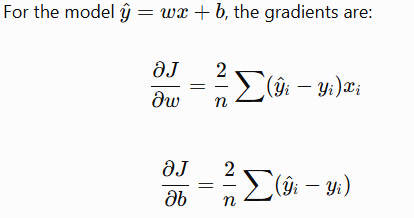

Parameter updates:
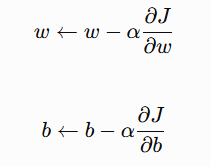\[
w \leftarrow w-\alpha\frac{\partial J}{\partial w}
\]

\[
b \leftarrow b-\alpha\frac{\partial J}{\partial b}
\]

Here, \(\alpha\) is the learning rate, which controls the size of each update.

In [ ]:
# Standardize using training data statistics
x_mu, x_sd = X_train.mean(), X_train.std()
y_mu, y_sd = y_train.mean(), y_train.std()

xtr = ((X_train.ravel() - x_mu) / x_sd)
xte = ((X_test.ravel() - x_mu) / x_sd)

ytr = (y_train - y_mu) / y_sd

# Initialize parameters
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000
n = len(xtr)

loss_history = []

for epoch in range(epochs):
    y_hat = w * xtr + b
    error = y_hat - ytr

    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Calculate gradients
    dw = (2 / n) * np.sum(error * xtr)
    db = (2 / n) * np.sum(error)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

print("Final weight:", w)
print("Final bias:", b)
print("Final training MSE (standardized):", loss_history[-1])

Final weight: 0.6906466049844351
Final bias: -2.782765404842919e-17
Final training MSE (standardized): 0.5230072654179475


**Gradient loss curve**

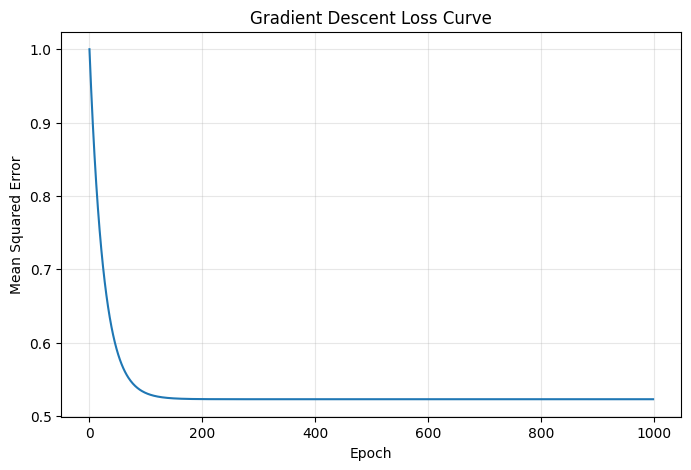

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Loss Curve")
plt.grid(True, alpha=0.3)
plt.show()

**Observations:**


*   The loss should decrease as the parameters improve.
*  A curve that flattens indicates that further updates produce smaller improvements.
* A loss that increases or oscillates excessively can indicate an unsuitable learning rate.
* More epochs do not automatically guarantee a better model; evaluate the final model on test data.


In [ ]:
# Predict on the test set using trained gradient descent parameters
y_pred_gd_scaled = w * xte + b

# Convert predictions back to the original house-value scale
y_pred_gd = y_pred_gd_scaled * y_sd + y_mu

# Calculate test-set metrics manually
gd_mse = np.mean((y_test - y_pred_gd) ** 2)
gd_mae = np.mean(np.abs(y_test - y_pred_gd))
gd_rmse = np.sqrt(gd_mse)
gd_r2 = r2_score(y_test, y_pred_gd)

print("SIMPLE LINEAR REGRESSION USING GRADIENT DESCENT")
print("Test MSE:", gd_mse)
print("Test RMSE:", gd_rmse)
print("Test MAE:", gd_mae)
print("Test R²:", gd_r2)

SIMPLE LINEAR REGRESSION USING GRADIENT DESCENT
Test MSE: 7091157771.408359
Test RMSE: 84209.01241202369
Test MAE: 62990.86530733777
Test R²: 0.45885918906572454


##**Part C — Multiple Linear Regression**

12. Theory
Multiple linear regression uses two or more independent variables to predict one continuous target.
image.png

For this dataset, we can use:
- median_income
- housing_median_age
- total_rooms
- total_bedrooms
- population
- households
- longitude
- latitude
The target remains median_house_value.

Unlike simple regression, the model can consider several housing characteristics simultaneously.


**13. Multiple regression without a machine-learning library**
We'll use NumPy's least-squares solver. This avoids a machine-learning model library, although NumPy itself is still a library.

In [ ]:
features = [
    "median_income",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "longitude",
    "latitude"
]

# Train/test split before calculating imputation values
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

# Impute missing values using training medians only
medians = train_df[features].median()

Xm_train = train_df[features].fillna(medians).to_numpy()
Xm_test = test_df[features].fillna(medians).to_numpy()

ym_train = train_df["median_house_value"].to_numpy()
ym_test = test_df["median_house_value"].to_numpy()

# Standardize using training statistics
xmean = Xm_train.mean(axis=0)
xstd = Xm_train.std(axis=0)
xstd[xstd == 0] = 1

Xtr = (Xm_train - xmean) / xstd
Xte = (Xm_test - xmean) / xstd

# Add the intercept column
Xtr_bias = np.column_stack([np.ones(len(Xtr)), Xtr])
Xte_bias = np.column_stack([np.ones(len(Xte)), Xte])

# Solve least squares manually
beta = np.linalg.lstsq(Xtr_bias, ym_train, rcond=None)[0]

ym_pred_manual = Xte_bias @ beta

print("Intercept:", beta[0])
print("Coefficients:", beta[1:])
print("Manual MSE:", np.mean((ym_test - ym_pred_manual) ** 2))
print("Manual MAE:", np.mean(np.abs(ym_test - ym_pred_manual)))

Intercept: 207194.6937378874
Coefficients: [ 77194.69946558  14905.90644754 -17805.41850057  48712.34334124
 -43766.49115918  17654.50065911 -85503.21815336 -90698.84880311]
Manual MSE: 5059928371.16536
Manual MAE: 51810.48362804256


This gives a baseline multiple regression model. Each coefficient indicates the direction and magnitude of the association between a feature and the predicted house value, holding the other included features fixed. Because the features have different units, interpret their magnitudes carefully.



**14. Multiple regression using scikit-learn**

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

multiple_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

multiple_model.fit(
    train_df[features],
    ym_train
)

ym_pred = multiple_model.predict(test_df[features])

print("Multiple Linear Regression")
print("MSE:", mean_squared_error(ym_test, ym_pred))
print("MAE:", mean_absolute_error(ym_test, ym_pred))
print("R²:", r2_score(ym_test, ym_pred))

Multiple Linear Regression
MSE: 5059928371.165347
MAE: 51810.48362804251
R²: 0.6138664756435184


**15. Compare simple and multiple regression**

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MSE": [
        mean_squared_error(y_test, y_pred_sklearn),
        mean_squared_error(ym_test, ym_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_sklearn),
        mean_absolute_error(ym_test, ym_pred)
    ],
    "R2 Score": [
        r2_score(y_test, y_pred_sklearn),
        r2_score(ym_test, ym_pred)
    ]
})

display(comparison)

,Model,MSE,MAE,R2 Score
0,Simple Linear Regression,7.091158e+09,62990.865301,0.458859
1,Multiple Linear Regression,5.059928e+09,51810.483628,0.613866


**Compare the metrics visually**

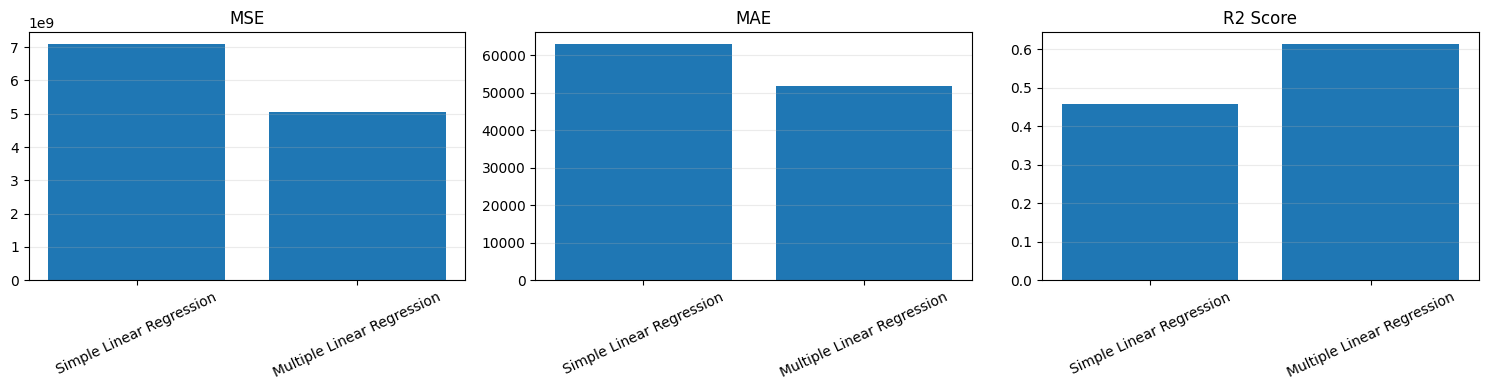

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["MSE", "MAE", "R2 Score"]

for ax, metric in zip(axes, metrics):
    ax.bar(comparison["Model"], comparison[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#**Part D — Polynomial Regression**

**16. Theory
Polynomial regression models a curved relationship by adding powers of the input variable.**

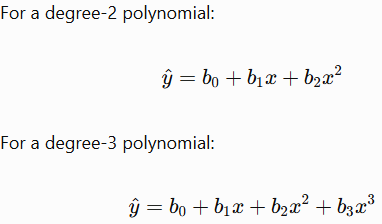

We will use median_income as the input and median_house_value as the target. This lets us compare a straight line against curved models.
17. Polynomial regression without a machine-learning model library
Here, we create polynomial features manually and solve the least-squares problem using NumPy.

In [ ]:
x_train_poly = X_train.ravel()
x_test_poly = X_test.ravel()

poly_models = {}
poly_predictions = {}

for degree in [1, 2, 3]:
    # Manually create x, x^2, x^3, as required
    A_train = np.column_stack(
        [x_train_poly ** power for power in range(1, degree + 1)]
    )
    A_test = np.column_stack(
        [x_test_poly ** power for power in range(1, degree + 1)]
    )

    # Add intercept
    A_train = np.column_stack([np.ones(len(A_train)), A_train])
    A_test = np.column_stack([np.ones(len(A_test)), A_test])

    # Fit model
    beta_poly = np.linalg.lstsq(A_train, y_train, rcond=None)[0]

    # Predict
    pred = A_test @ beta_poly

    poly_models[degree] = beta_poly
    poly_predictions[degree] = pred

    print(f"\nDegree {degree}")
    print("MSE:", mean_squared_error(y_test, pred))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("R²:", r2_score(y_test, pred))


Degree 1
MSE: 7091157771.76555
MAE: 62990.86530093756
R²: 0.45885918903846656

Degree 2
MSE: 7032732680.932144
MAE: 62829.15588701914
R²: 0.46331772769346236

Degree 3
MSE: 6982964744.960327
MAE: 62189.632169635894
R²: 0.4671156210838622


**19. Plot the polynomial regression curves**


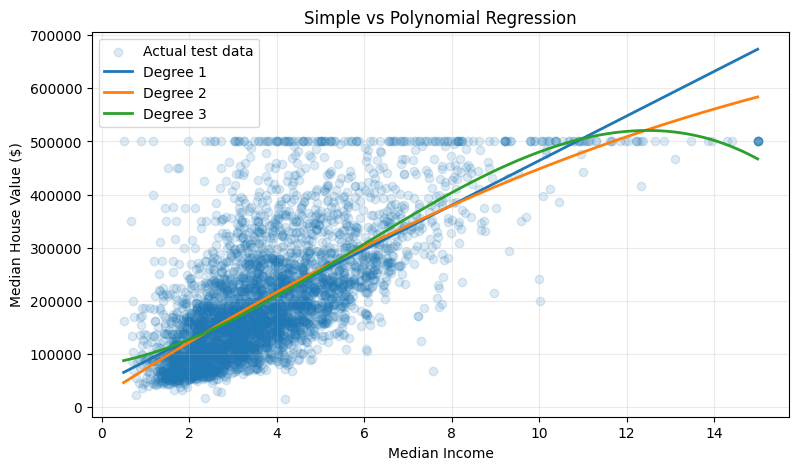

In [ ]:
x_grid = np.linspace(
    X_train.min(),
    X_train.max(),
    300
).reshape(-1, 1)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_test.ravel(),
    y_test,
    alpha=0.15,
    label="Actual test data"
)

for degree in [1, 2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    plt.plot(
        x_grid.ravel(),
        model.predict(x_grid),
        linewidth=2,
        label=f"Degree {degree}"
    )

plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")
plt.title("Simple vs Polynomial Regression")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

A curved line may capture patterns that a straight line misses. However, a higher-degree model can also overfit. Select a degree using validation performance, not merely how well the curve follows the training data.

#**Part E — Locally Weighted Linear Regression (LWLR)**

**20. What is locally weighted regression?**

Ordinary linear regression learns one global line for the entire dataset. Locally weighted linear regression fits a local line around each query point, giving greater weight to nearby observations.

A common weight function is the Gaussian kernel:
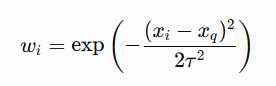

Where:
- \(x_q\) is the point for which we want a prediction.
- \(x_i\) is a training point.
- \(\tau\) controls how local the fit is.
- Nearby points receive higher weights than distant points.
Unlike ordinary linear regression, LWLR repeats the weighted fit for each query point. It is therefore more computationally expensive.

**21. Implement LWLR manually**

This implementation uses only NumPy for the algorithm. We use a subset of the training data and evaluate on a subset of the test data to keep the Colab execution manageable.

In [ ]:
# Use the same simple-regression train/test split
rng = np.random.default_rng(42)

train_n = min(2000, len(X_train))
test_n = min(300, len(X_test))

train_ids = rng.choice(
    len(X_train), train_n, replace=False
)
test_ids = rng.choice(
    len(X_test), test_n, replace=False
)

x_lw_train = X_train[train_ids].ravel()
y_lw_train = y_train[train_ids]

x_lw_test = X_test[test_ids].ravel()
y_lw_test = y_test[test_ids]

def lwlr_predict(x_query, x_train, y_train, tau=0.5):
    predictions = []

    # Design matrix for a local straight line
    X_design = np.column_stack([
        np.ones(len(x_train)),
        x_train
    ])

    for xq in np.asarray(x_query).ravel():
        distances = x_train - xq

        weights = np.exp(
            -(distances ** 2) / (2 * tau ** 2)
        )

        # Weighted least-squares fit
        weighted_X = X_design * weights[:, None]
        weighted_y = y_train * weights

        beta = np.linalg.pinv(X_design.T @ weighted_X) @ (
            X_design.T @ weighted_y
        )

        predictions.append(beta[0] + beta[1] * xq)

    return np.array(predictions)

lw_pred = lwlr_predict(
    x_lw_test,
    x_lw_train,
    y_lw_train,
    tau=0.5
)

print("LWLR MSE:", mean_squared_error(y_lw_test, lw_pred))
print("LWLR MAE:", mean_absolute_error(y_lw_test, lw_pred))
print("LWLR R²:", r2_score(y_lw_test, lw_pred))

LWLR MSE: 5891333825.428861
LWLR MAE: 58778.927043561715
LWLR R²: 0.5809223568706151


**22. Plot the locally weighted regression curve**

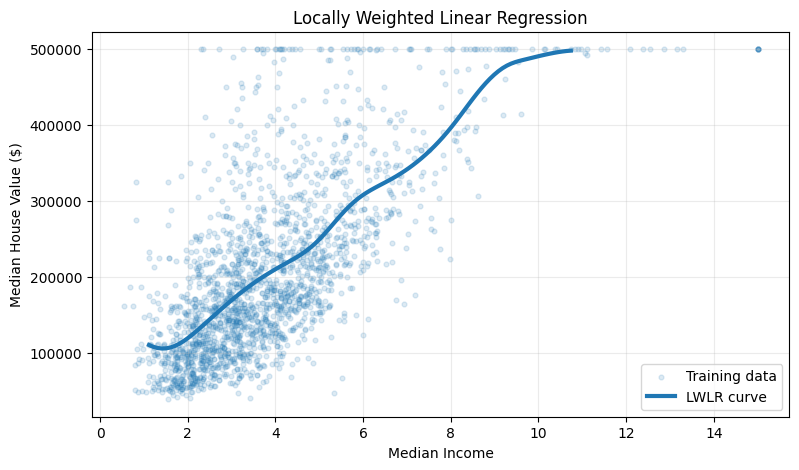

In [ ]:
x_grid_lw = np.linspace(
    np.percentile(x_lw_train, 1),
    np.percentile(x_lw_train, 99),
    100
)

y_grid_lw = lwlr_predict(
    x_grid_lw,
    x_lw_train,
    y_lw_train,
    tau=0.5
)

plt.figure(figsize=(9, 5))

plt.scatter(
    x_lw_train,
    y_lw_train,
    alpha=0.15,
    s=12,
    label="Training data"
)

plt.plot(
    x_grid_lw,
    y_grid_lw,
    linewidth=3,
    label="LWLR curve"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")
plt.title("Locally Weighted Linear Regression")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

Analysis: A smooth curved line indicates that local fits are capturing changing relationships across income levels. A smaller \(\tau\) makes the model more local and potentially more sensitive to noise; a larger \(\tau\) makes the fit smoother. LWLR has no single global coefficient pair that describes all query points.

#**Part F — Final comparison and evaluation**

**23. Compare the regression models**


In [ ]:
results = [
    {
        "Model": "Simple Linear",
        "MSE": mean_squared_error(y_test, y_pred_sklearn),
        "MAE": mean_absolute_error(y_test, y_pred_sklearn),
        "R2": r2_score(y_test, y_pred_sklearn)
    },
    {
        "Model": "Multiple Linear",
        "MSE": mean_squared_error(ym_test, ym_pred),
        "MAE": mean_absolute_error(ym_test, ym_pred),
        "R2": r2_score(ym_test, ym_pred)
    },
    {
        "Model": "Polynomial Degree 2",
        "MSE": mean_squared_error(y_test, poly_predictions[2]),
        "MAE": mean_absolute_error(y_test, poly_predictions[2]),
        "R2": r2_score(y_test, poly_predictions[2])
    },
    {
        "Model": "Polynomial Degree 3",
        "MSE": mean_squared_error(y_test, poly_predictions[3]),
        "MAE": mean_absolute_error(y_test, poly_predictions[3]),
        "R2": r2_score(y_test, poly_predictions[3])
    },
    {
        "Model": "LWLR (test subset)",
        "MSE": mean_squared_error(y_lw_test, lw_pred),
        "MAE": mean_absolute_error(y_lw_test, lw_pred),
        "R2": r2_score(y_lw_test, lw_pred)
    }
]

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,MSE,MAE,R2
0,Simple Linear,7.091158e+09,62990.865,0.459
1,Multiple Linear,5.059928e+09,51810.484,0.614
2,Polynomial Degree 2,7.032733e+09,62829.156,0.463
3,Polynomial Degree 3,6.982965e+09,62189.632,0.467
4,LWLR (test subset),5.891334e+09,58778.927,0.581


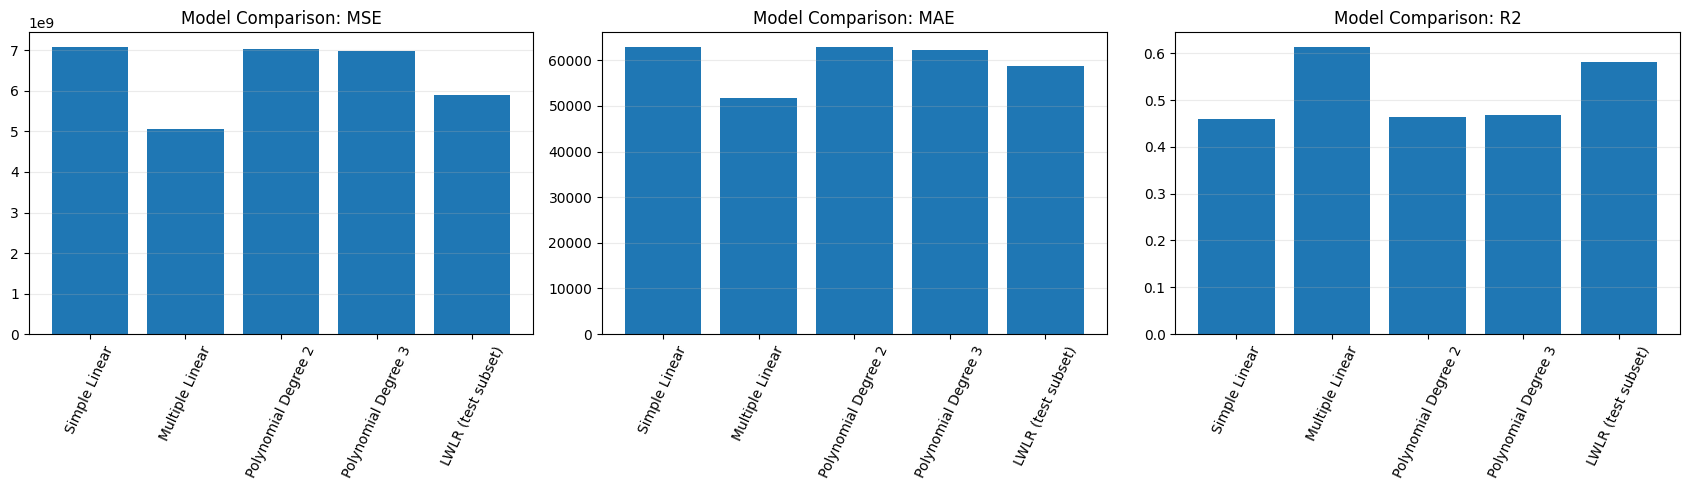

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, ["MSE", "MAE", "R2"]):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(f"Model Comparison: {metric}")
    ax.tick_params(axis="x", rotation=65)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

MSE: lower is better; penalizes large mistakes.



MAE: lower is better; represents average absolute error.



R²: values closer to 1 indicate that the model explains more of the target variation relative to a constant-mean baseline. A negative test \(R^2\) is possible.

**24. Verify manual and library evaluation metrics**



In [ ]:

manual_mse = np.mean((y_test - y_pred_manual) ** 2)
manual_mae = np.mean(np.abs(y_test - y_pred_manual))

library_mse = mean_squared_error(y_test, y_pred_manual)
library_mae = mean_absolute_error(y_test, y_pred_manual)

metric_comparison = pd.DataFrame({
    "Metric": ["MSE", "MAE"],
    "Manual Calculation": [manual_mse, manual_mae],
    "Library Calculation": [library_mse, library_mae]
})

display(metric_comparison)

print("MSE values match:",
      np.isclose(manual_mse, library_mse))
print("MAE values match:",
      np.isclose(manual_mae, library_mae))

,Metric,Manual Calculation,Library Calculation
0,MSE,7.091158e+09,7.091158e+09
1,MAE,6.299087e+04,6.299087e+04


MSE values match: True
MAE values match: True


##**AI Trends and Applications of Regression Models**
Artificial Intelligence and Machine Learning are increasingly used to analyze data, identify patterns and make predictions. Regression techniques play an important role in predictive analytics because they help estimate continuous numerical values from historical data.

**Current AI Trends Related to Regression**

1. Explainable AI (XAI): Explainable AI focuses on making machine learning predictions understandable. Regression models are useful because their coefficients and relationships can help explain how input features influence predictions.

2. Automated Machine Learning (AutoML): AutoML automates tasks such as data preprocessing, model selection and hyperparameter tuning. It helps simplify the development and evaluation of machine learning models.

3. Predictive Analytics: Regression models are widely used to predict future values based on historical data. They help organizations make informed decisions using data-driven predictions.

4. Hybrid Machine Learning Models: Regression techniques can be combined with other machine learning algorithms to improve prediction accuracy and handle complex datasets.

**Real-World Applications of Regression**
- Real Estate: Predicting property prices using location, area, number of rooms and other housing characteristics.
- Healthcare: Predicting medical costs and estimating patient recovery-related numerical outcomes.
- Finance: Forecasting revenue, expenses and financial trends.
- Agriculture: Predicting crop yield based on rainfall, temperature and soil-related parameters.
- Business Analytics: Forecasting sales, product demand and future revenue.



##**Limitations and Future Scope**
**Limitations**
1. Simple Linear Regression considers only one independent variable and may not capture all factors affecting house prices.
2. Polynomial Regression with higher degrees may lead to overfitting if the model becomes unnecessarily complex.
3. Locally Weighted Linear Regression requires repeated calculations for different query points, making it computationally expensive.
4. The prediction performance depends on the quality and completeness of the dataset.
5. Regression models may not capture every complex relationship present in real-world housing data.

**Future Scope**
1. Apply feature selection techniques to identify the most important housing attributes.
2. Perform hyperparameter tuning to improve model performance.
3. Use cross-validation to obtain more reliable model evaluation results.
4. Explore advanced regression algorithms such as Ridge Regression, Lasso Regression and Elastic Net.
5. Develop an interactive housing price prediction application using the trained regression model.
6. Use additional housing datasets to evaluate the generalization capability of the models.

## **Conclusion**

In this practical, regression models were developed to predict median house values using the California Housing dataset. Simple linear regression was implemented using mathematical formulas and scikit-learn. Multiple linear regression used several housing features, while polynomial regression was used to investigate nonlinear relationships. Gradient descent was implemented to optimize model parameters, and its loss curve was analyzed. Locally weighted linear regression was also implemented to demonstrate local fitting.

Model performance was evaluated using Mean Squared Error (MSE), Mean Absolute Error (MAE), and the coefficient of determination (R²). The comparison showed how model complexity and feature selection affect predictive performance. The final model should be selected based on test performance, validation results, computational cost, and interpretability. Further improvements could include hyperparameter tuning, cross-validation, categorical feature encoding, and evaluation on additional datasets.